# Q8 - Churn predictor

A small tool to use the model from notebook 07:
- enter a player's features in a form and get a prediction,
- every prediction is saved in `data/07_model_output/predictions_log.csv`,
- a SHAP chart explains why,
- you can also score a whole file of players.

How to use: run all cells, fill the form in section 2 and click **Predict and save**. Each field starts at the median player. Change what you know and leave the rest. You get a warning if a value is outside what the model has seen (for example a negative count).

How to read it: churn risk = 1 - P(still active). The player is "at risk" when the churn risk is above the threshold. The model is moderate (about 0.8 ROC-AUC): use it to rank players, not as a certainty.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'src'))  # not needed after `pip install -e .`

from ubi_churn.config import DataCatalog, load_params

catalog = DataCatalog.from_config()  # conf/base/catalog.yml
params = load_params()  # conf/base/parameters.yml

from datetime import datetime

import ipywidgets as w
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import clear_output, display

from ubi_churn.utils import ml

LOG_PATH: Path = catalog.path('predictions_log')
artifact: dict = catalog.load('churn_model')
predictor = ml.ChurnPredictor(artifact)
FEATURES: list[str] = predictor.features
FEATURE_INFO: dict = predictor.feature_info
DEFAULTS: dict = predictor.defaults
RANGES: dict = predictor.ranges
THRESHOLD: float = predictor.threshold
print(predictor.summary())
print('metrics:', artifact['metrics'])
print(artifact['note'])

model trained on 840 players (2026-10-16) | churn-risk threshold 0.50
metrics: {'cv_roc_auc': '0.820 +/- 0.032', 'cv_pr_auc': '0.808 +/- 0.029', 'holdout_roc_auc': 0.841, 'holdout_pr_auc': 0.809}
Predicts P(still_active). Label is noisy (91 players flagged active are silent for 90+ days). Expect ROC-AUC about 0.8.


## 1. Prediction function

`predict_one` predicts one player and saves the result in the log. The model logic is in `src/ubi_churn/utils/ml.py`.

In [2]:
def predict_one(player_id: str, values: dict, store: bool = True) -> pd.Series:
    # predict one player and (optionally) append the result to the log
    res = predictor.predict(predictor.player_frame(player_id, values))
    if store:
        ml.append_predictions(res, LOG_PATH)
    return res.iloc[0]

## 2. Form: enter a player, predict, save

In [3]:
player_id = w.Text(value='', description='Player id', placeholder='any name or id', style={'description_width': '220px'}, layout=w.Layout(width='520px'))
inputs: dict[str, w.FloatText] = {}
rows = [player_id]
for f in FEATURES:
    label, unit = FEATURE_INFO[f]
    lo, hi = RANGES[f]
    inputs[f] = w.FloatText(value=round(DEFAULTS[f], 3), description=label, style={'description_width': '220px'}, layout=w.Layout(width='520px'))
    rows.append(w.HBox([inputs[f], w.HTML(f"<small>&nbsp;{unit} | training range {lo:.3g} - {hi:.3g}</small>")]))
use_default = w.Checkbox(value=False, description='Reset all fields to the median player')
button = w.Button(description='Predict and save', button_style='primary', icon='check')
out = w.Output()


def on_reset(change):
    if change['new']:
        for f in FEATURES:
            inputs[f].value = round(DEFAULTS[f], 3)
        use_default.value = False


def on_click(_):
    with out:
        clear_output()
        pid = player_id.value.strip() or f"player_{datetime.now().strftime('%H%M%S')}"
        values = {f: inputs[f].value for f in FEATURES}
        warnings = predictor.check_inputs(values)
        if warnings:
            display(w.HTML("<div style='color:#d35400;width:520px'><b>Check the inputs:</b><br>" + '<br>'.join(warnings) + '</div>'))
        res = predict_one(pid, values)
        colour = '#c0392b' if res['churn_risk'] >= THRESHOLD else '#27ae60'
        display(w.HTML(
            f"<div style='border:2px solid {colour};padding:10px;width:520px'>"
            f"<b>{pid}</b><br><span style='font-size:20px;color:{colour}'>{res['prediction']}</span><br>"
            f"P(still active) = {res['p_active']:.1%} | churn risk = {res['churn_risk']:.1%} (threshold {THRESHOLD:.0%})<br>"
            f"<small>saved to {LOG_PATH}</small></div>"
        ))
        predictor.plot_waterfall(pd.DataFrame([values]), f'Why this churn risk: {pid}')


use_default.observe(on_reset, names='value')
button.on_click(on_click)
display(w.VBox(rows + [use_default, button, out]))

## 3. Saved predictions

Run this cell again after new predictions to refresh it.

4 stored predictions | at risk: 3


,timestamp,player_id,p_active,churn_risk,prediction,days_since_last_match,matches_last_30d,matches_last_90d,matches,tenure_days,sessions_per_week,share_night,stay_after_loss,share_pvp_ranked,n_modes,win_rate,kd_ratio
3,2026-10-16T15:31:38,player_153137,0.244,0.756,At risk (likely churn),99.808,0.0,0.0,27.5,55.771,1.653,0.168,0.5,0.0,2.0,0.489,0.863
2,2026-10-16T15:25:52,player_152552,0.244,0.756,At risk (likely churn),99.808,0.0,0.0,27.5,55.771,1.653,0.168,0.5,0.0,2.0,0.489,0.863
1,2026-10-16T15:25:35,player_152535,0.668,0.332,At risk (likely churn),10.000,6.0,20.0,27.5,55.771,1.653,0.168,0.5,0.0,2.0,0.489,0.863
0,2026-10-16T15:24:44,player_152444,0.244,0.756,At risk (likely churn),99.808,0.0,-6.0,27.5,55.771,1.653,0.168,0.5,0.0,2.0,0.489,0.863


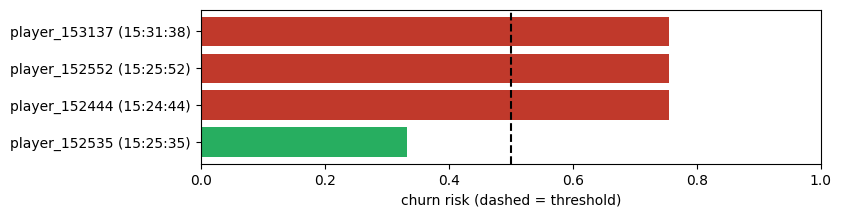

In [4]:
df_log = ml.load_predictions(LOG_PATH)
if df_log.empty:
    print('no stored prediction yet: use the form above')
else:
    print(len(df_log), 'stored predictions | at risk:', int((df_log['churn_risk'] >= THRESHOLD).sum()))
    display(df_log[['timestamp', 'player_id', 'p_active', 'churn_risk', 'prediction'] + FEATURES].sort_values('timestamp', ascending=False))
    fig, ax = plt.subplots(figsize=(8, max(2, 0.4 * len(df_log))))
    d = df_log.sort_values('churn_risk')
    ax.barh(d['player_id'].astype(str) + ' (' + d['timestamp'].str[11:] + ')', d['churn_risk'], color=np.where(d['churn_risk'] >= THRESHOLD, '#c0392b', '#27ae60'))
    ax.axvline(THRESHOLD, color='black', linestyle='--')
    ax.set_xlim(0, 1)
    ax.set_xlabel('churn risk (dashed = threshold)')
    plt.show()

## 4. Score a whole file

Set `SCORE_PATH` to a CSV or parquet file with one row per player (e.g. `catalog.path('player_features')`). The result is saved in `data/07_model_output/<name>_scored.csv`, and added to the log if `STORE = True`.

In [5]:
SCORE_PATH: Path | None = None  # e.g. catalog.path('player_features') or Path('my_players.csv')
STORE: bool = False

if SCORE_PATH is None:
    print('set SCORE_PATH to score a file')
else:
    df_in = pd.read_parquet(SCORE_PATH) if SCORE_PATH.suffix == '.parquet' else pd.read_csv(SCORE_PATH)
    if 'player_id' not in df_in.columns:
        df_in.insert(0, 'player_id', df_in['playerid'] if 'playerid' in df_in.columns else range(len(df_in)))
    df_res = predictor.predict(df_in[['player_id'] + [f for f in FEATURES if f in df_in.columns]])
    scored_path = LOG_PATH.parent / f'{SCORE_PATH.stem}_scored.csv'
    df_res.to_csv(scored_path, index=False)
    if STORE:
        ml.append_predictions(df_res, LOG_PATH)
    print(len(df_res), 'players scored | at risk:', int((df_res['churn_risk'] >= THRESHOLD).sum()), '| saved to', scored_path)
    display(df_res.sort_values('churn_risk', ascending=False).head(20))

set SCORE_PATH to score a file


## 5. SHAP: why does the model predict churn?

All 840 training players. Each dot is a player: on the right it raises the churn risk, on the left it lowers it. Red = high value of the feature. The bar chart shows the average impact of each feature.

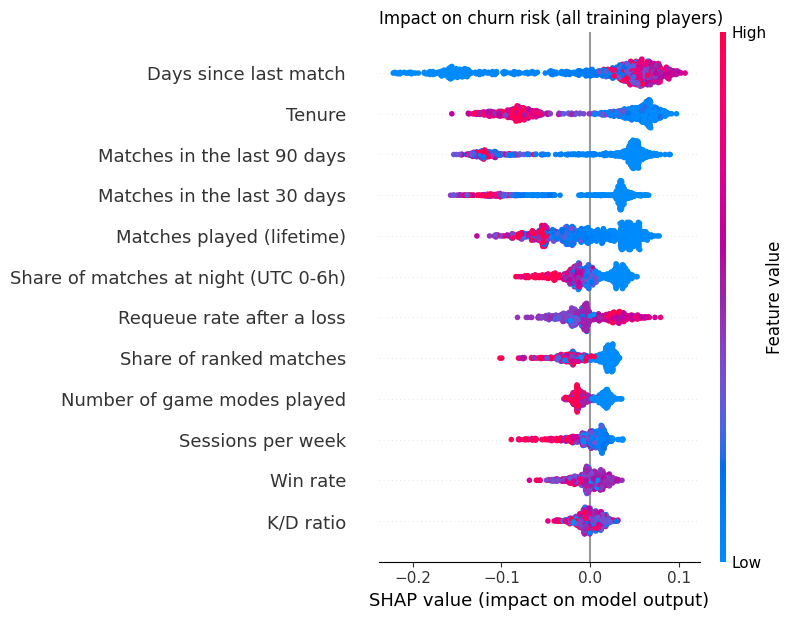

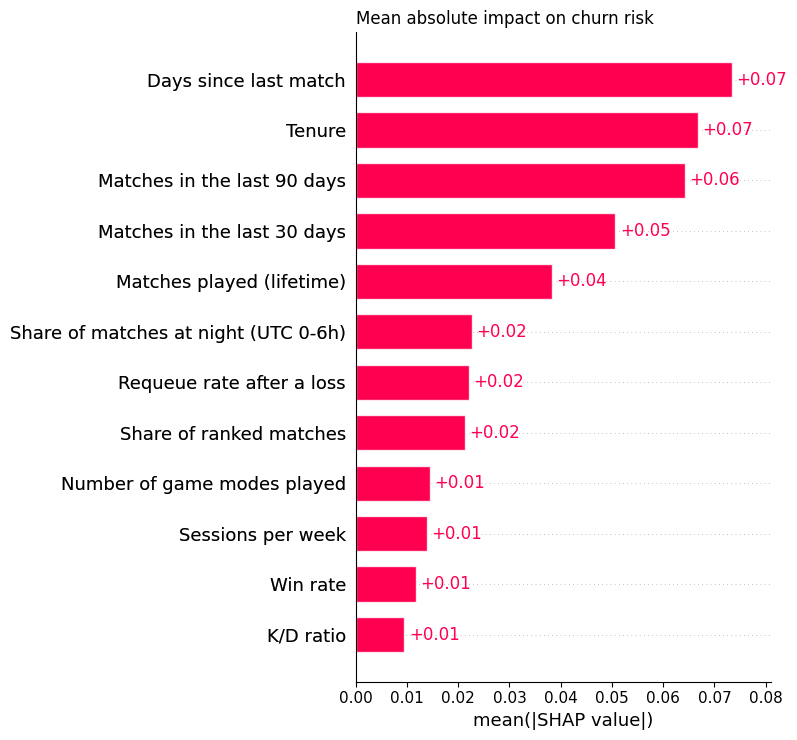

In [6]:
df_all = catalog.load('player_features').to_pandas()
ml.plot_shap_summary(predictor.explain(df_all), 'Impact on churn risk (all training players)')

Explain one saved prediction: `STORED_INDEX` is its position in the log (-1 = the latest).

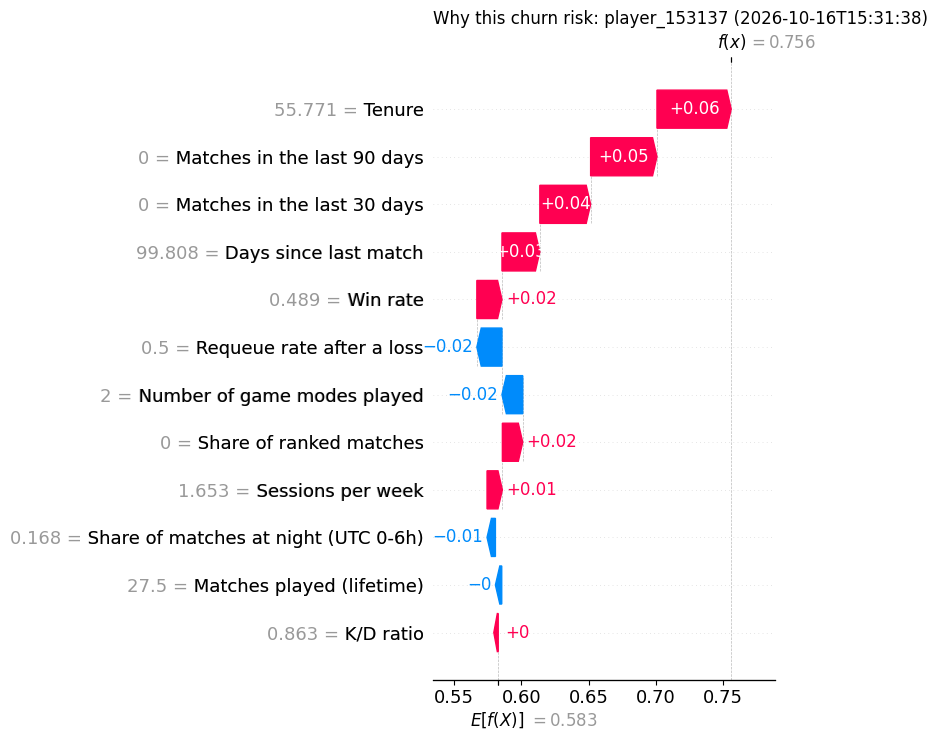

In [7]:
STORED_INDEX: int = -1

df_log = ml.load_predictions(LOG_PATH)
if df_log.empty:
    print('no stored prediction yet: use the form above')
else:
    row = df_log.iloc[[STORED_INDEX]]
    predictor.plot_waterfall(row, f"Why this churn risk: {row['player_id'].iloc[0]} ({row['timestamp'].iloc[0]})")

## 6. Quick check (nothing is saved)

Two examples: a regular recent player and a player who has been silent for a long time. The first should get a low churn risk, the second a high one.

In [8]:
examples = {
    'regular recent player': dict(days_since_last_match=2, matches_last_30d=40, matches_last_90d=120, matches=300, tenure_days=250, sessions_per_week=5, share_pvp_ranked=0.5, n_modes=3),
    'silent one-timer': dict(days_since_last_match=200, matches_last_30d=0, matches_last_90d=0, matches=3, tenure_days=1, sessions_per_week=1, share_pvp_ranked=0.0, n_modes=1),
}
print('input warnings:', {name: predictor.check_inputs(vals) for name, vals in examples.items()})
pd.DataFrame([predict_one(name, vals, store=False) for name, vals in examples.items()])[['player_id', 'p_active', 'churn_risk', 'prediction']]

input warnings: {'regular recent player': [], 'silent one-timer': []}


,player_id,p_active,churn_risk,prediction
0,regular recent player,0.992,0.008,Likely still active
0,silent one-timer,0.066,0.934,At risk (likely churn)


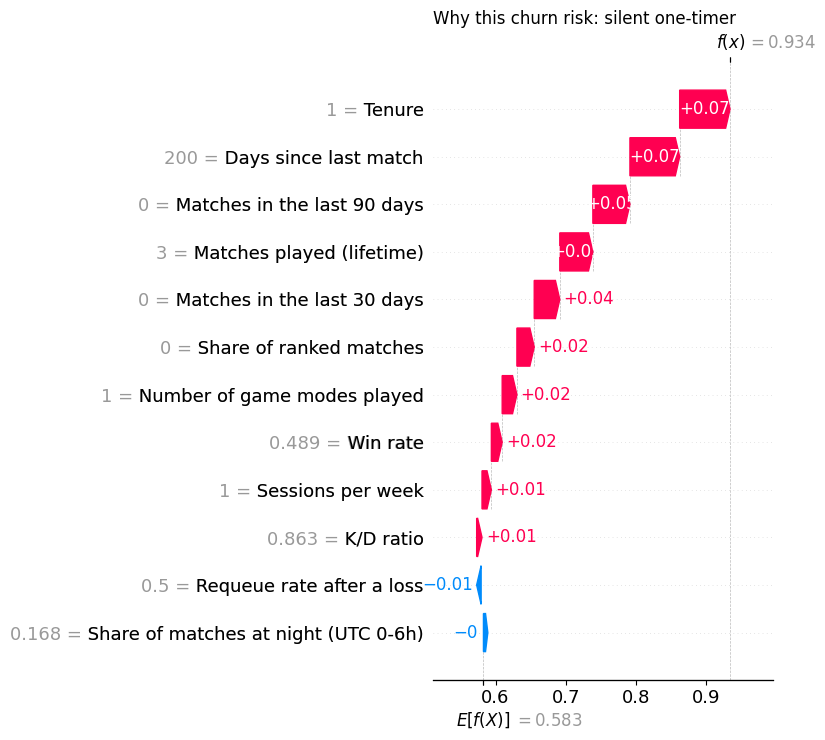

In [9]:
predictor.plot_waterfall(pd.DataFrame([examples['silent one-timer']]), 'Why this churn risk: silent one-timer')